In [127]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.optimize import curve_fit
import scipy.constants as pc
import astropy.units as u
from astropy.io import fits
from astropy.coordinates import SkyCoord
from astropy.table import Table
from astropy.table import vstack
from astropy.cosmology import FlatLambdaCDM
from scipy.stats import ttest_rel
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import AutoMinorLocator
import os
from matplotlib.gridspec import GridSpec
import h5py
import emcee
import corner

FIG_DIR = "/raid/scratch/work/alberttg/Masters_project/Plots"

DATA_PRODUCTS_PATH = "/raid/scratch/work/alberttg/Masters_project/Data_products"

POSTERIOR_PATH = '/raid/scratch/work/austind/GALFIND_WORK/Bagpipes/pipes/posterior'

In [128]:
def gaussian_function(x, sigma, mu):
    """
    1D Gaussian for a histogram density plot. The amplitude is dependent on sigma.
    """
    amp = 1 / (sigma * np.sqrt(2 * np.pi))

    y = amp * np.exp( - ((x - mu)**2) / (2 * sigma**2) )

    return y

In [129]:
def _parse_err(err, n):
    """
    Normalize an error specification into (err_lo, err_hi) arrays of length n.

    Accepted forms for `err`:
      - None                            -> zeros (no error)
      - scalar or 1D array of length n  -> symmetric error (same as before)
      - [err_high, err_low]             -> asymmetric error; each of
        err_high/err_low can be a scalar (applied to all points) or a
        length-n array (per-point)

    Returned lo/hi are positive distances from the central value
    (lower bound = value - lo, upper bound = value + hi).
    """
    if err is None:
        return np.zeros(n), np.zeros(n)

    # Asymmetric: [err_high, err_low]
    if isinstance(err, (list, tuple)) and len(err) == 2:
        hi = np.asarray(err[0], dtype=float) 
        lo = np.asarray(err[1], dtype=float)
        if hi.ndim == 0:
            hi = np.full(n, float(hi))
        if lo.ndim == 0:
            lo = np.full(n, float(lo))
        return lo.copy(), hi.copy()

    # Symmetric: scalar or array, same as before
    arr = np.asarray(err, dtype=float)
    if arr.ndim == 0:
        arr = np.full(n, float(arr))
    return arr.copy(), arr.copy()


def fit_gaussian_mcmc(x_in, y_in, x_err=None, y_err=None, x_pivot=None,
                     n_walkers=32, n_steps=5000, plot=True, save_path=None):
    """
    Bayesian gaussian fit without intrinsic scatter,
    supporting asymmetric measurement errors in both x and y (but we have none here).

    x_err / y_err each accept:
      - None, a scalar, or a 1D array of length N (symmetric errors, same
        as before), OR
      - [err_high, err_low] for asymmetric errors, where each of
        err_high/err_low is a scalar (applied to every point) or a
        length-N array (per-point).

    Asymmetric-error handling
    --------------------------
    Each data point's error distribution is modeled as a split-normal
    (two-piece Gaussian): width `sigma_lo` below the measured value and
    `sigma_hi` above it. At every MCMC step, for each point we compare the
    model prediction to the data (delta = model - data) and pick the
    error side consistent with that comparison:
        delta >= 0  ->  use the "hi" error (model sits above the data)
        delta <  0  ->  use the "lo" error (model sits below the data)
    This is applied to both the y errors and the x errors (the latter
    projected into y-space via the slope, m^2 * xerr^2, as in the
    symmetric case). This is the standard practical approximation for
    asymmetric errors in a likelihood — it is exact only when the true
    error distribution really is split-normal, but works well in general
    and reduces to the ordinary symmetric-error likelihood when lo == hi.
    The intrinsic scatter term sigma_int is kept symmetric.
    """
    # --- Step 1: Data Cleaning & Pivot Handling ---
    x = np.asarray(x_in, dtype=float)
    y = np.asarray(y_in, dtype=float)
    n = len(x)

    xe_lo, xe_hi = _parse_err(x_err, n)
    ye_lo, ye_hi = _parse_err(y_err, n)
    # xe_lo = np.zeros(n)
    # xe_hi = np.zeros(n)
    # ye_lo = np.zeros(n)
    # ye_hi = np.zeros(n)
    # My basic version of _parse_err function 

    xp = 0.0 if x_pivot is None else x_pivot
    
    mask = (
        np.isfinite(x) & np.isfinite(y)
        & np.isfinite(xe_lo) & np.isfinite(xe_hi)
        & np.isfinite(ye_lo) & np.isfinite(ye_hi)
    )

    x, y = x[mask], y[mask]
    xe_lo, xe_hi = xe_lo[mask], xe_hi[mask]
    ye_lo, ye_hi = ye_lo[mask], ye_hi[mask]
    n = len(x)

    # Guard against zero/negative error entries (keeps likelihood well-defined)
    xe_lo = np.where(xe_lo <= 0, 1e-10, xe_lo)
    xe_hi = np.where(xe_hi <= 0, 1e-10, xe_hi)
    ye_lo = np.where(ye_lo <= 0, 1e-10, ye_lo)
    ye_hi = np.where(ye_hi <= 0, 1e-10, ye_hi)

    #print(xe_lo)
    #print(xe_hi)
    #print(ye_lo)
    #print(ye_hi)

    if len(x) < 2:
        raise ValueError("Not enough finite data points.")

    # --- Step 2: Robust Initial Guess ---
    try:
        popt, pcov = curve_fit(gaussian_function, x - xp, y, p0=[np.std(x-xp), np.mean(x-xp)])
        guess_sig, guess_mu = popt
        print(f"Guesses: sig = {guess_sig:.3f}, mean = {guess_mu:.3f}")
    
    except np.linalg.LinAlgError:
        guess_sig, guess_mu = np.std(x-xp), np.mean(x-xp)

    # guess_std = np.std(y - gaussian_function(x-xp, guess_sig, guess_mu, guess_amp))

    # --- Step 3: MCMC Functions (3 parameters: m, c, sigma_int) ---
    def log_likelihood(theta, x, y, xerr_lo, xerr_hi, yerr_lo, yerr_hi, xp):
        sig, mu = theta
        # if sigma_int <= 0: this was one of the params
        #    return -np.inf

        model = gaussian_function(x, sig, mu)
        # delta = model - y  # positive => model above data

        delta = x - xp

        y_err = np.where(delta >= 0, yerr_hi, yerr_lo)
        x_err = np.where(delta >= 0, xerr_hi, xerr_lo)

        n = len(x) # no. of data points

        ln_L = -0.5 * np.sum(np.log(2 * np.pi * y_err**2)) - 0.5 * np.sum(((y - model) / y_err)**2)
        # ln_L = - (n/2) * np.log(2*np.pi) - n * np.log(sig) - 0.5 * np.sum( ((delta - mu)  / sig)**2)

        return ln_L

    # Set prior limits safely outside empirical distribution boundaries
    min_sig, max_sig = 1e-4, guess_sig * 3.0
    min_mu, max_mu = guess_mu - (3 * guess_sig), guess_mu + (3 * guess_sig)

    def log_prior(theta): 
        """
        Uses Jeffrey's prior (log-uniform) instead of flat uniform prior.
        """
        sig, mu = theta
        if min_sig < sig < max_sig and min_mu < mu < max_mu:
            return -np.log(sig) # This is return 0 for flat uniform prior
        return -np.inf

    def log_probability(theta, x, y, xerr_lo, xerr_hi, yerr_lo, yerr_hi, xp):
        lp = log_prior(theta)
        if not np.isfinite(lp):
            return -np.inf
        ll = log_likelihood(theta, x, y, xerr_lo, xerr_hi, yerr_lo, yerr_hi, xp)
        return lp + ll 
    #if np.isfinite(ll) else -np.inf

    # --- Step 4: Run MCMC ---
    ndim = 2
    # initial = np.array([guess_sig, guess_mu, guess_amp if guess_std > 0 else 0.1]) old
    initial = np.array([guess_sig, guess_mu])
    pos = initial + 1e-4 * np.random.randn(n_walkers, ndim)

    sampler = emcee.EnsembleSampler(
        n_walkers, ndim, log_probability,
        args=(x, y, xe_lo, xe_hi, ye_lo, ye_hi, xp)
    )
    sampler.run_mcmc(pos, n_steps, progress=True)

    flat_samples = sampler.get_chain(discard=1000, thin=15, flat=True)

    x_range = np.linspace(x.min(), x.max(), 100)
    sig_samples = flat_samples[:, 0]
    mu_samples = flat_samples[:, 1]
    # ------------------------------------------------------ intrinsic scatter was a parameter here but we are fitting to a histogram

    models = gaussian_function((x_range - xp), sig_samples[:, np.newaxis], mu_samples[:, np.newaxis])

    sig_med, mu_med = np.median(flat_samples, axis=0)
    lower_bound = np.percentile(models, 16, axis=0)
    upper_bound = np.percentile(models, 84, axis=0)

    amp_samples = 1 / (flat_samples[:, 0] * np.sqrt(2 * np.pi)) # get amp back out
    amp_med = np.median(amp_samples, axis=0)
    amp_16 = np.percentile(amp_samples, 16)
    amp_84 = np.percentile(amp_samples, 84)


    # --- Step 5: Visualization ---
    if plot:
        plt.figure(figsize=(8, 6))
        print(f"Median sigma: {sig_med:.3f}, mean: {mu_med:.3f}, amplitude: {amp_med:.3f}")

        # matplotlib expects asymmetric errors as [lower_distances, upper_distances]
        plt.errorbar(
            x, y,
            xerr=[xe_lo, xe_hi], yerr=[ye_lo, ye_hi],
            fmt=".k", alpha=0.4, label="Data", zorder=1
        )
        plt.fill_between(x_range, lower_bound, upper_bound, color="royalblue", alpha=0.3, label=r"1$\sigma$ Confidence")
        plt.plot(x_range, gaussian_function((x_range - xp), sig_med, mu_med), color="darkblue", lw=2, label="Median Fit")
        plt.legend()
        if save_path:
            plt.savefig(save_path, dpi=150, bbox_inches="tight")
        plt.show()

        labels = [r"Sigma $\sigma$", f"Mean $\mu$ (at $x={xp}$)", "Amplitude"]
        corner.corner(flat_samples, labels=labels, truths=[sig_med, mu_med], show_titles=True)
        plt.show()

    sig_16 = np.percentile(flat_samples[:, 0], 16)
    sig_84 = np.percentile(flat_samples[:, 0], 84)

    amp_16 = sig_16 / (sig_med**2 * np.sqrt(2*np.pi))
    amp_84 = sig_84 / (sig_med**2 * np.sqrt(2*np.pi))

    results = {
        "sigma_median": sig_med,
        "mean_median": mu_med,
        "amplitude": amp_med,
        "sig_16": np.percentile(flat_samples[:, 0], 16),
        "sig_84": np.percentile(flat_samples[:, 0], 84),
        "mu_16": np.percentile(flat_samples[:, 1], 16),
        "mu_84": np.percentile(flat_samples[:, 1], 84),
        "amp_16": amp_16,
        "amp_84": amp_84,
        "x_pivot": xp,
    }

    return results

In [130]:
def get_posterior(sample_table, SFH_model):
    """
    Finding the paths to the stellar mass posterior, based on galaxy survey id, survey and SFH model used in BAGPIPES.
    Each galaxy has its own posterior.
    """

    surveys = np.asarray(sample_table["SURVEY"].data, dtype=str)

    survey_ids = np.asarray(sample_table["#ID"].data, dtype=int)

    redshifts = np.asarray(sample_table["input_redshift"].data, dtype=float)

    mass = np.asarray(sample_table["stellar_mass_50"].data, dtype=float)

    posteriors = []

    for i in range(len(sample_table)):

        gal_id = survey_ids[i]
        survey = surveys[i]
        redshift = redshifts[i]

        if survey in ["CEERSP1", "CEERSP2", "CEERSP3", "CEERSP4", "CEERSP5", "CEERSP6", "CEERSP7", "CEERSP8", "CEERSP9", "CEERSP10", "NEP-1", "NEP-2", "NEP-3", "NEP-4", "NGDEEP"]:

            path = os.path.join(POSTERIOR_PATH, f"v14_psfmatch_F444W_empirical/{survey}/ACS_WFC+NIRCam/0.32as/{SFH_model}/{gal_id}.h5")

        elif survey in ["PRIMER-COSMOS","PRIMER-UDS"]:
                
            path = os.path.join(POSTERIOR_PATH, f"v12_psfmatch_F444W_empirical/{survey}/ACS_WFC+NIRCam/0.32as/{SFH_model}/{gal_id}.h5")


        elif survey in ["JADES-DR3-GS-East", "JADES-DR3-GS-North", "JADES-DR3-GS-South", "JADES-DR3-GS-West", "JADES-DR3-GN-Parallel", "JADES-DR3-GN-Medium", "JADES-DR3-GN-Deep"]:

            path = os.path.join(POSTERIOR_PATH, f"v13_psfmatch_F444W_empirical/{survey}/ACS_WFC+NIRCam/0.32as/{SFH_model}/{gal_id}.h5")
            
        else:
            print(f"Galaxy {gal_id} could not be found in these surveys")
            print(f"Check survey {survey}")
            continue


        with h5py.File(path,'r') as hf:
            # Print all root level object names (aka keys) 
            # these can be group or dataset names 
            # print("Keys: %s" % hf['basic_quantities'].keys())
            # print("Keys: %s" % hf['advanced_quantities'].keys())
            stellar_mass = hf['basic_quantities']['stellar_mass'][:]
            

        median_mass = np.median(stellar_mass)
        log_mass = np.array(stellar_mass - median_mass)

        if len(log_mass) != 500:
            print("Length not 500: ", len(log_mass))
            print(f"Check the posterior of galaxy {gal_id} in survey {survey} ")

        posteriors.append(log_mass) # ought to be in same order as mass and redshift are ordered, which is by ith row of sample table

    # print(posteriors)
    
    plot_binned_posterior(mass, redshifts, posteriors, 50) # I think the posterior are in the same order as galaxy table (mass, redshift...)

    

In [131]:
def plot_binned_posterior(mass, redshift, posterior, histogram_bins):
    """
    Sorting the posterior into bins, selected by mass and redshift value.

    mass : array of floats
        The mass values of all the galaxies
    redshift : array of floats
        The zfix redshift values of all the galaxies
    posterior : array of arrays of floats
        The posterior for each galaxy, which are each an array.
    histogram_bins : float
        Number of histogram bins for each plot and also for gaussian fitting
    """
    # z_bins = [[6.5, 7.5], [7.5, 8.5], [8.5, 9.5], [9.5, 10.5], [10.5, 11.5], [11.5, 13.5]]
    z_bins = [[6.5, 7.5], [7.5, 8.5], [9.5, 10.5], [10.5, 13.5]]

    fig, axes = plt.subplots(3, 4, figsize=(30,20), constrained_layout=False)
    # Starting binning, bin by mass first (vertical bins)
    # mass_bins = np.linspace(mass.min(), mass.max(), n_mass_bins + 1)
    # mass_bins = [[mass_bins[i], mass_bins[i + 1]] for i in range(len(mass_bins) - 1)]
    # mass_bins.reverse()
    #print("Mass bins: ", mass_bins)
    mass_bins = [[9,11], [7,9], [6,7]] # Have put them in reverse for the gridspec plotting

    for i in range(len(mass_bins)):
        
        bin_width = mass_bins[i][1] - mass_bins[i][0]

        mass_bin_mask = (mass >= mass_bins[i][0]) & (mass < mass_bins[i][1]) # Splitting into mass bins

        redshift_m_binned = redshift[mass_bin_mask]
        mass_errors_m_binned = mass[mass_bin_mask]
        
        posterior_m_binned = [item for item, m in zip(posterior, mass_bin_mask) if m]


        # Now bin by z (horizontal bins)
        for j in range(len(z_bins)):
            
            z_bin_mask = (redshift_m_binned >= z_bins[j][0]) & (redshift_m_binned < z_bins[j][1])

            redshift_z_binned = redshift_m_binned[z_bin_mask]
            mass_z_binned = mass_errors_m_binned[z_bin_mask] # x axis values now binned by z and mass

            print("m bin: ", mass_bins[i])
            print("z bin: ", z_bins[j])
            print("Number of gals in bin: ", len(redshift_z_binned))

            posterior_z_binned = [item for item, m in zip(posterior_m_binned, z_bin_mask) if m]

            # [print(len(p)) for p in posterior_z_binned] # this checks that most posterior are length 500, but one is 106 and one is 107

            if len(posterior_z_binned) == 0:
                continue  # or leave the axis empty

            # --------------------------- binning complete ----------------------------
            # Now calculating posterior sum and making into a normalised histogram

            posterior_sum = np.concatenate(posterior_z_binned, axis=0)  # was trying this to see combined distribution of mass offsets for the galaxies in a bin
            # posterior_sum = [sum(p) for p in zip(*posterior_z_binned)] # idk about this one...
            # print("sum shape: ", np.shape(posterior_sum))
            
            raw_counts, edges = np.histogram(posterior_sum, bins=histogram_bins)
            centres = 0.5 * (edges[1:] + edges[:-1])
            yerr = np.sqrt(np.maximum(raw_counts, 1)) # Poisson errors on hist density

            # Calculate the normalization factor used by density=True
            bin_widths = np.diff(edges)
            total_counts = len(posterior_sum)
            normalization = total_counts * bin_widths

            # Calculate density and its corresponding scaled error
            counts = raw_counts / normalization
            # Apply Poisson error on raw counts, safely handling zero-bins with np.maximum
            yerr = np.sqrt(np.maximum(raw_counts, 1)) / normalization
            print("yerr :", yerr)
            # print("x : ", centres)
            # print("y : ", counts)

            # MCMC fitting
            results = fit_gaussian_mcmc(centres, counts, x_err=None, y_err=yerr, n_walkers=32, n_steps=5000, plot=True)
            

            # ----------------------------------- Plotting ------------------------------------
            
            ax = axes[i,j]
                    
            # ax.set_ylabel(r'Probability density \left( $\sigma_{M_\star}^{-1}$ \right)', fontsize=16)
            if j == 0:
                ax.set_ylabel(rf"${mass_bins[i][0]} ≤ \log_{10}(M_\star/M_\odot) < {mass_bins[i][1]}$", fontsize=16)
            
            ax.grid(True)

            ax.tick_params(
                    axis="both",
                    which="major",
                    labelsize=14,
                    length=8,
                    width=1.5,
                    direction="in",
                    top=True,
                    right=True
                    )
            
            ax.xaxis.set_minor_locator(AutoMinorLocator(5))
            ax.yaxis.set_minor_locator(AutoMinorLocator(5))

            ax.tick_params(
                    axis="both",
                    which="minor",
                    length=4,
                    width=1,
                    direction="in",
                    top=True,
                    right=True
                    )

            ax.hist(posterior_sum, bins=histogram_bins, color='steelblue', density=True) # Try to normalise????
            #N = len(mass_errors_binned)

            legend_text = rf"${z_bins[j][0]} ≤ z < {z_bins[j][1]}$"
            ax.text(0.6, 0.95, legend_text, transform=ax.transAxes, fontsize=15, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))

    # fig.supylabel(r'Galaxy Stellar Mass $\log_{10}(M_\star/M_\odot)$', fontsize=19)
    fig.supxlabel(r'Stellar Mass $\log_{10}(M_\star/M_\odot) - \langle( \log_{10}(M_\star/M_\odot) \rangle $', fontsize=19)
    plt.tight_layout()
    fig_path = os.path.join(FIG_DIR, "gridspec_mass_errors.png")
    fig.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.close(fig)


Length not 500:  106
Check the posterior of galaxy 11825 in survey NEP-4 
Length not 500:  117
Check the posterior of galaxy 96942 in survey PRIMER-UDS 
m bin:  [9, 11]
z bin:  [6.5, 7.5]
Number of gals in bin:  50
yerr : [0.00107093 0.00107093 0.00107093 0.00107093 0.00107093 0.00107093
 0.00107093 0.00107093 0.00107093 0.00262324 0.00214187 0.00239468
 0.00302906 0.00302906 0.00370983 0.00428374 0.00556474 0.00386131
 0.00576716 0.00605812 0.00576716 0.00668798 0.00808538 0.01004626
 0.01118089 0.01315986 0.01211624 0.01396328 0.01620618 0.01876429
 0.02338956 0.03202076 0.04748481 0.07123124 0.08462416 0.06774878
 0.04812061 0.03817998 0.02885568 0.02259139 0.01830014 0.01392215
 0.00963841 0.00734196 0.00633573 0.00490764 0.00370983 0.00283343
 0.00185491 0.00107093]
Guesses: sig = 0.064, mean = 0.001


100%|██████████| 5000/5000 [00:06<00:00, 743.05it/s]


Median sigma: 0.070, mean: 0.004, amplitude: 5.680


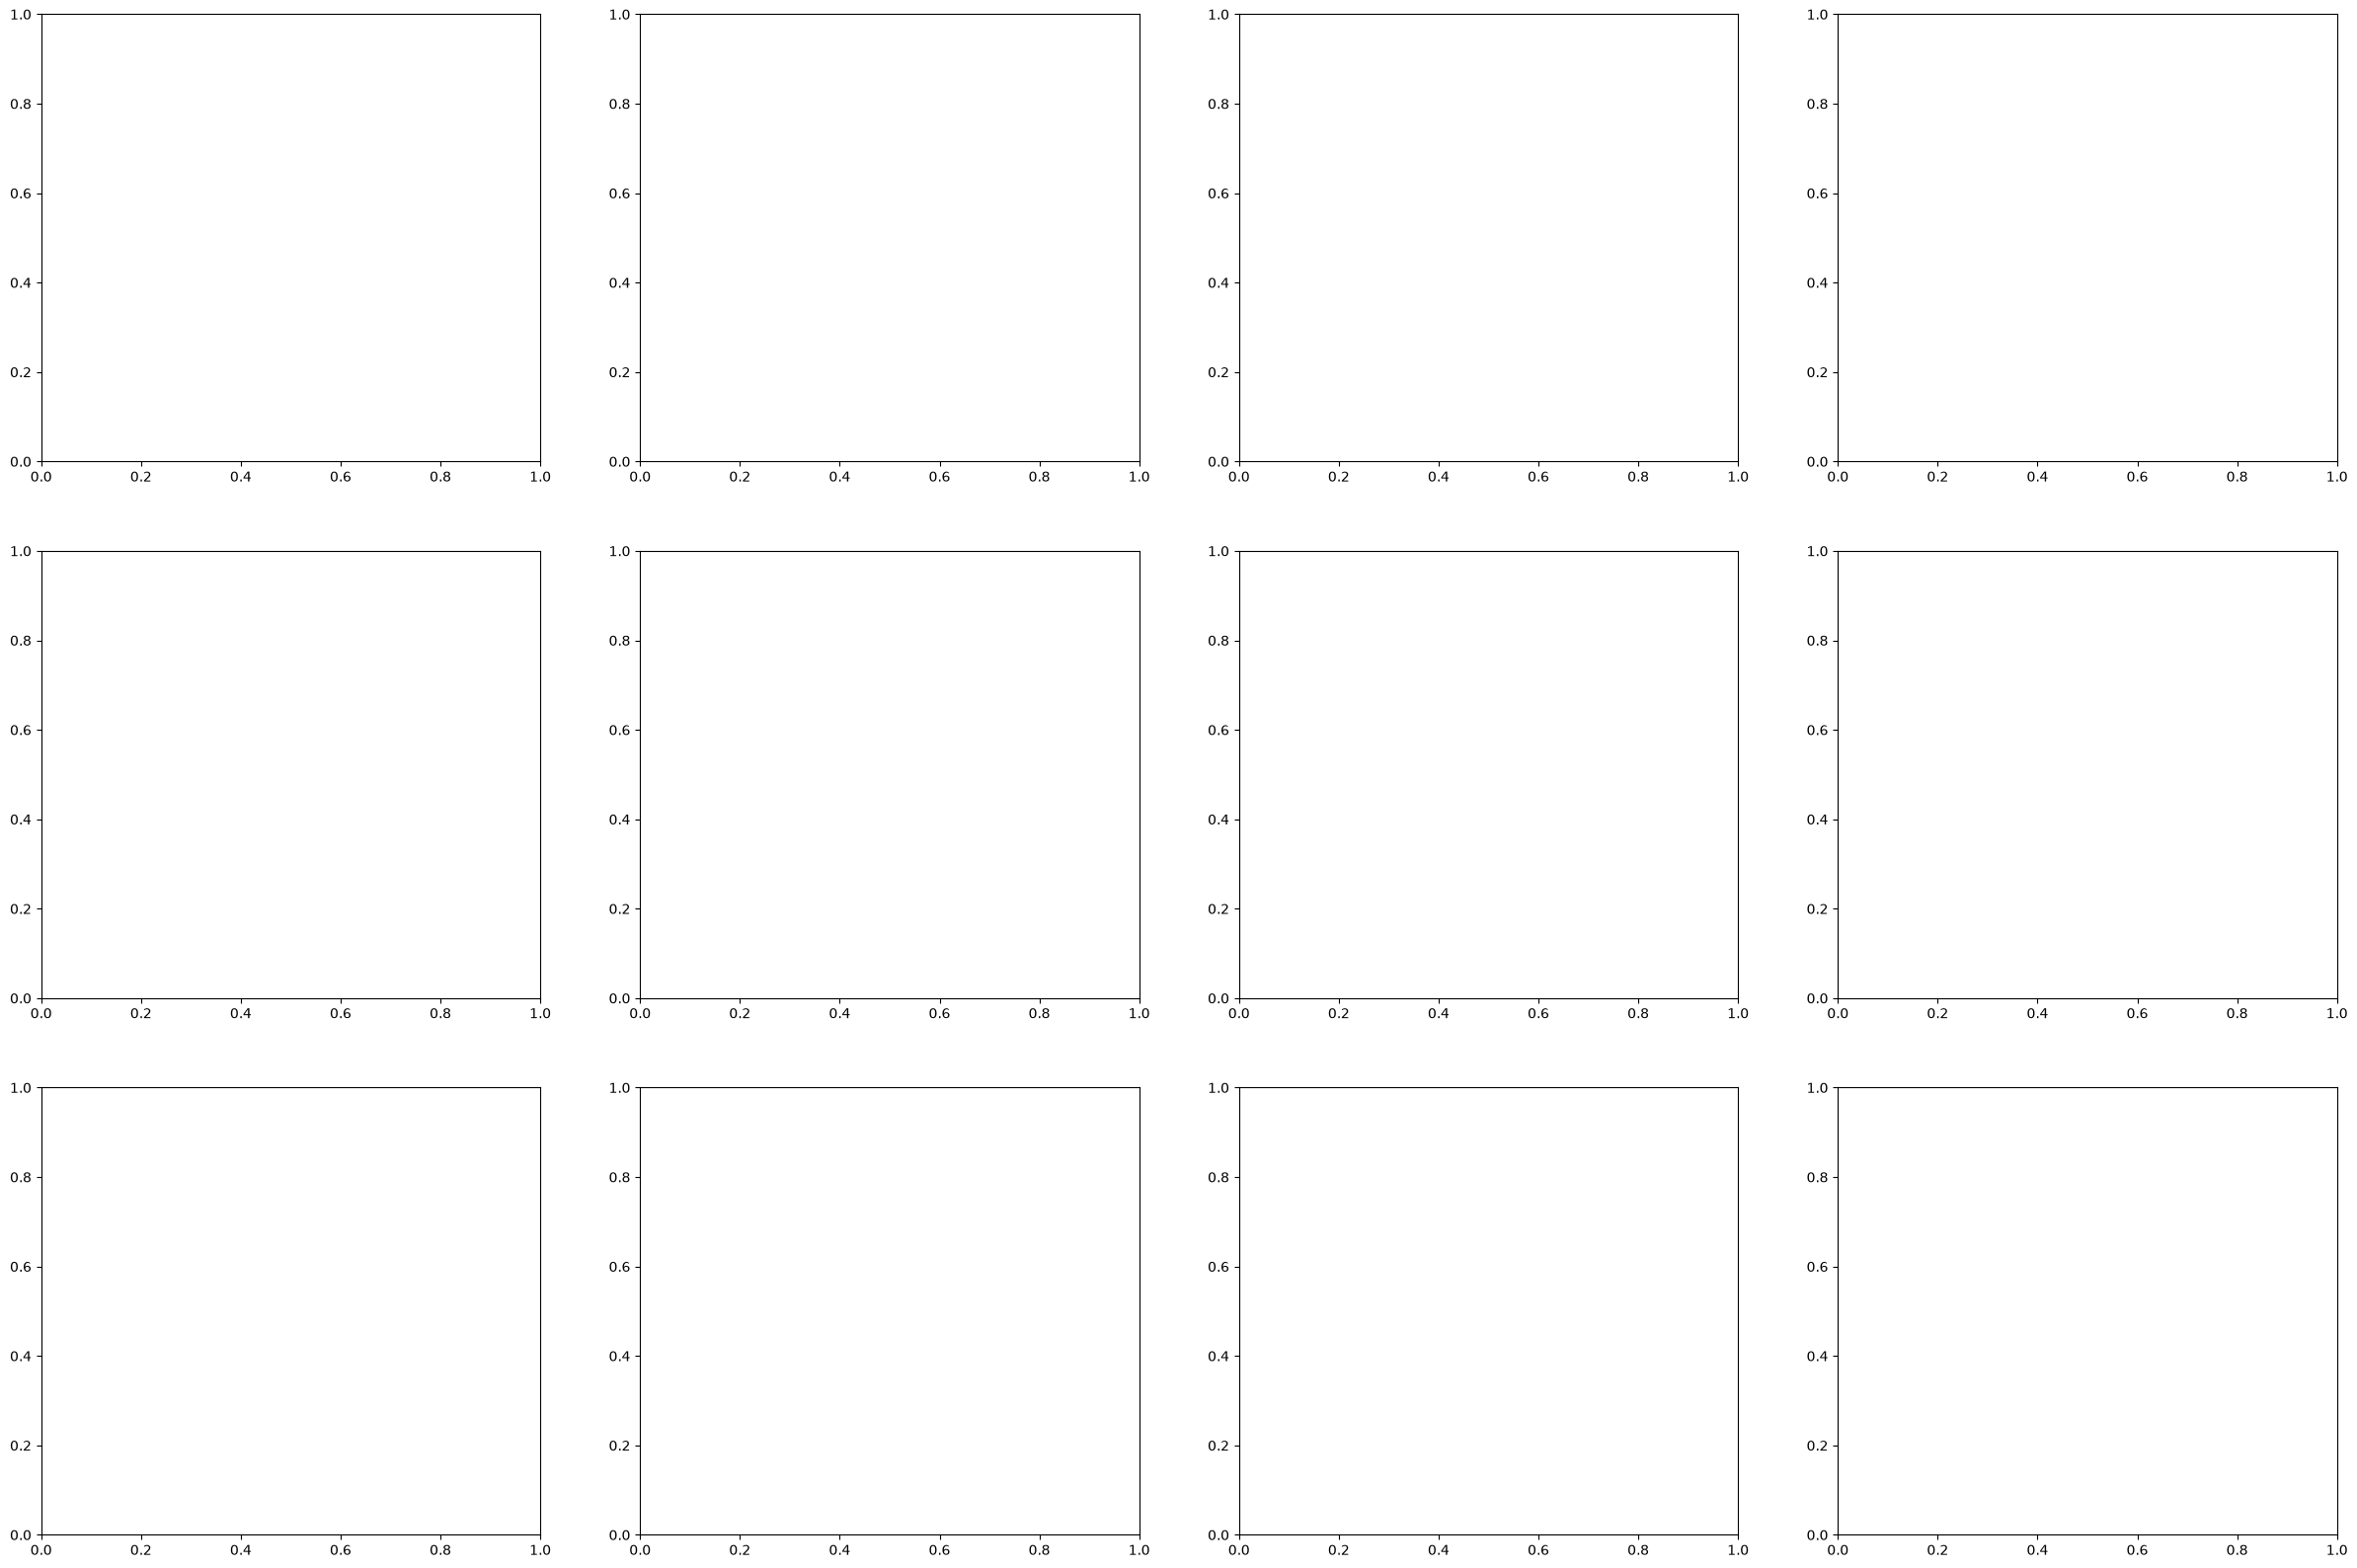

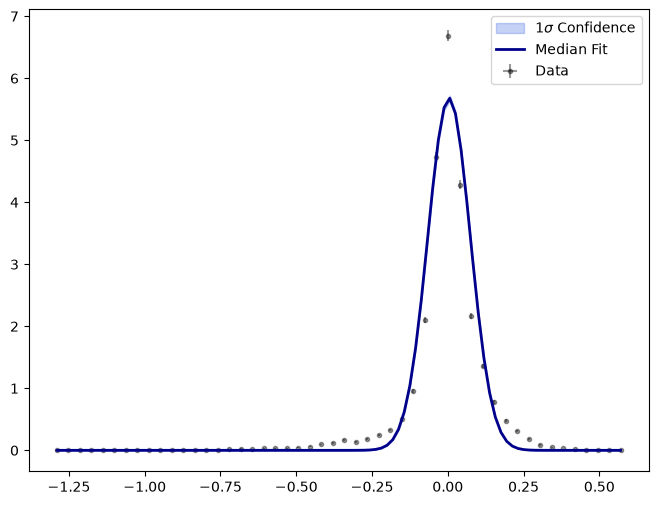

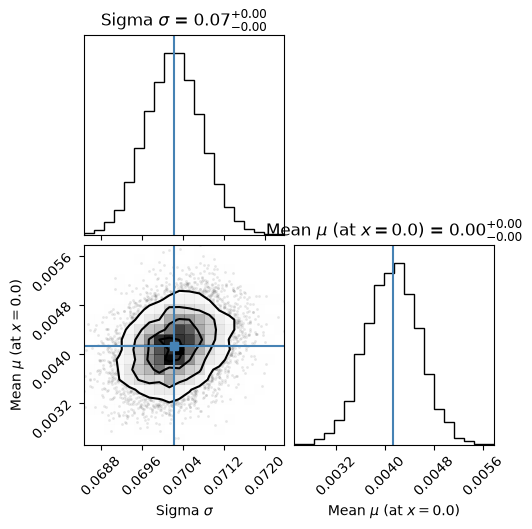

m bin:  [9, 11]
z bin:  [7.5, 8.5]
Number of gals in bin:  10
yerr : [0.01376344 0.00688172 0.00973222 0.00973222 0.01376344 0.01376344
 0.00973222 0.01376344 0.01376344 0.01538799 0.02282408 0.02837406
 0.03300357 0.03077599 0.04767795 0.04129032 0.05240962 0.05285949
 0.05999344 0.07151693 0.07347666 0.08595265 0.11307819 0.15233336
 0.17998032 0.19790179 0.18593382 0.14086529 0.11117758 0.0814256
 0.07282927 0.06193548 0.04616398 0.03953247 0.02481239 0.02481239
 0.02176191 0.02574904 0.03077599 0.02999672 0.02064516 0.02665279
 0.01820732 0.0168567  0.01191949 0.01946444 0.0168567  0.01538799
 0.00688172 0.00688172]
Guesses: sig = 0.073, mean = 0.002


100%|██████████| 5000/5000 [00:07<00:00, 705.38it/s]


Median sigma: 0.077, mean: 0.002, amplitude: 5.199


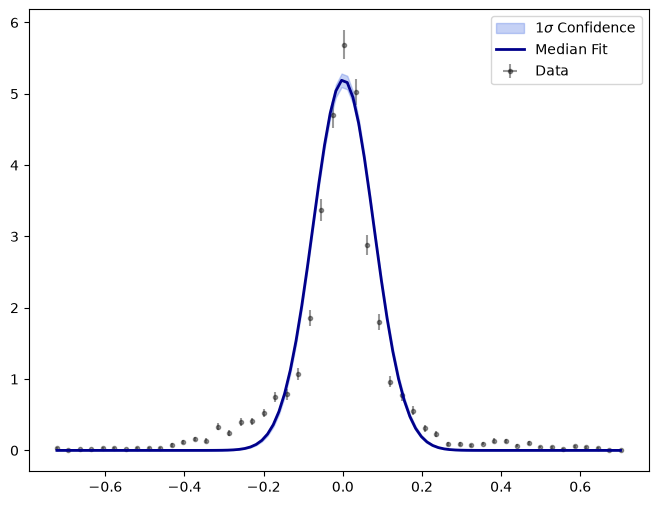

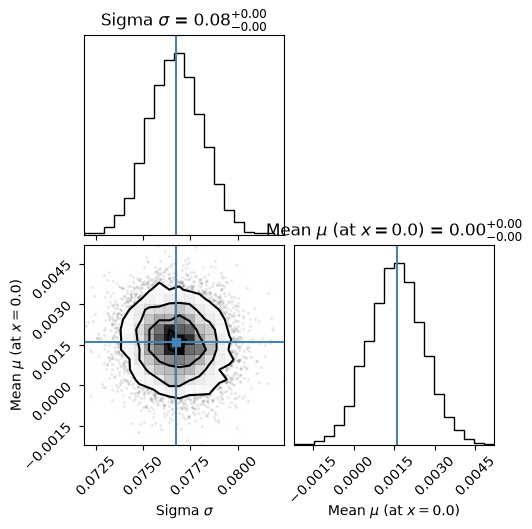

m bin:  [9, 11]
z bin:  [9.5, 10.5]
Number of gals in bin:  5
yerr : [0.01516906 0.01072615 0.01516906 0.01516906 0.01516906 0.03033813
 0.01857823 0.01857823 0.01516906 0.01516906 0.01857823 0.02837872
 0.0214523  0.02837872 0.02627359 0.03557461 0.03217844 0.03033813
 0.02837872 0.03033813 0.03217844 0.02627359 0.03391906 0.04796879
 0.03391906 0.03867368 0.0214523  0.0214523  0.02627359 0.03715647
 0.05972066 0.07734735 0.09350839 0.07954724 0.13396955 0.17559461
 0.25563361 0.25742755 0.16823306 0.13396955 0.08308439 0.05972066
 0.04290459 0.01516906 0.0239844  0.01516906 0.01857823 0.01072615
 0.01857823 0.01516906]
Guesses: sig = 0.063, mean = 0.006


100%|██████████| 5000/5000 [00:06<00:00, 799.10it/s]


Median sigma: 0.064, mean: 0.006, amplitude: 6.188


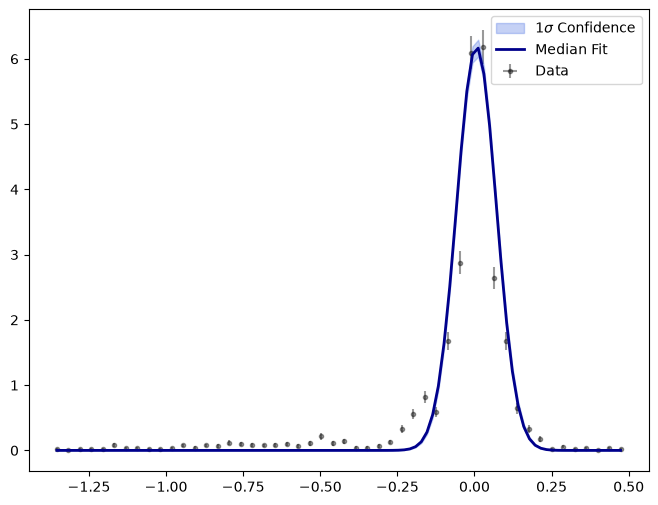

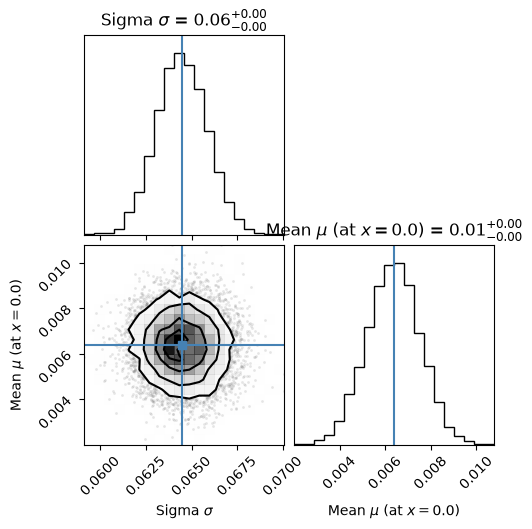

m bin:  [9, 11]
z bin:  [10.5, 13.5]
Number of gals in bin:  29
yerr : [0.00144848 0.00250883 0.00323889 0.00383231 0.00458048 0.00458048
 0.00647778 0.008446   0.00738581 0.00806478 0.00892901 0.01140532
 0.01335429 0.01381759 0.01185629 0.01083941 0.01121985 0.01140532
 0.01074219 0.01121985 0.01103127 0.01083941 0.01140532 0.01167799
 0.01167799 0.01112596 0.01121985 0.01158781 0.01381759 0.01419211
 0.01695398 0.02113982 0.02562617 0.03014084 0.03592105 0.04335762
 0.04958785 0.06591762 0.07460709 0.05903319 0.04381492 0.03589183
 0.02875144 0.0244531  0.02123883 0.01803339 0.01566767 0.01638764
 0.0085693  0.00631376]
Guesses: sig = 0.126, mean = 0.009


100%|██████████| 5000/5000 [00:06<00:00, 719.28it/s]


Median sigma: 0.143, mean: 0.003, amplitude: 2.800


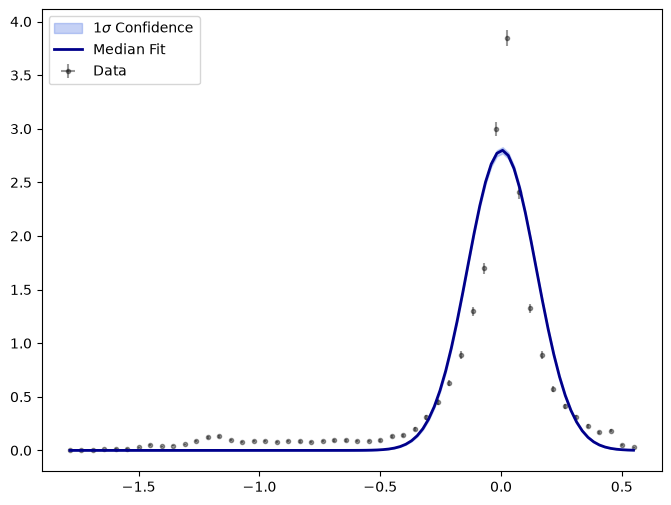

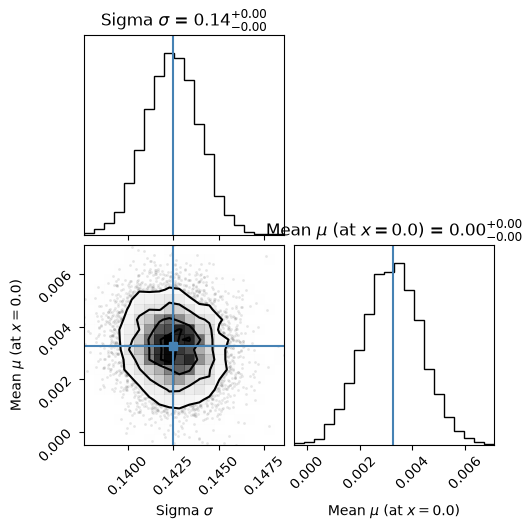

m bin:  [7, 9]
z bin:  [6.5, 7.5]
Number of gals in bin:  1066
yerr : [1.00088265e-04 7.46013883e-05 1.15571974e-04 1.52887351e-04
 1.97376721e-04 2.18774216e-04 2.85051505e-04 4.19363329e-04
 5.07069977e-04 5.35885197e-04 7.46013883e-04 8.91478787e-04
 1.10349551e-03 1.31941155e-03 1.58253443e-03 1.85606095e-03
 2.16986189e-03 2.57239607e-03 3.14070959e-03 3.84613388e-03
 4.70639578e-03 5.81804744e-03 7.57643120e-03 9.50926313e-03
 9.87013301e-03 8.40820860e-03 7.02711815e-03 5.90643271e-03
 5.05696174e-03 4.31296686e-03 3.70191303e-03 3.12507700e-03
 2.60806283e-03 2.18723332e-03 1.81390326e-03 1.53649886e-03
 1.30584398e-03 1.07125100e-03 8.04173900e-04 6.35645856e-04
 5.00441327e-04 4.20688335e-04 3.07589404e-04 2.64808659e-04
 1.91654437e-04 1.15571974e-04 1.00088265e-04 8.82695531e-05
 3.33627551e-05 4.71820607e-05]
Guesses: sig = 0.152, mean = -0.002


100%|██████████| 5000/5000 [00:06<00:00, 723.89it/s]


Median sigma: 0.177, mean: 0.009, amplitude: 2.257


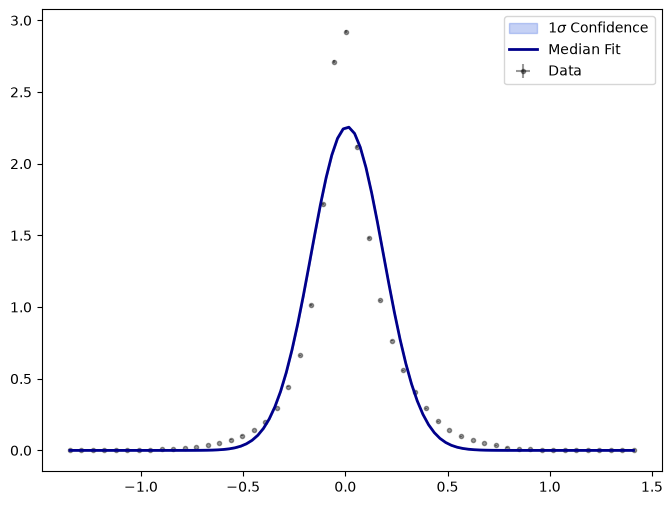

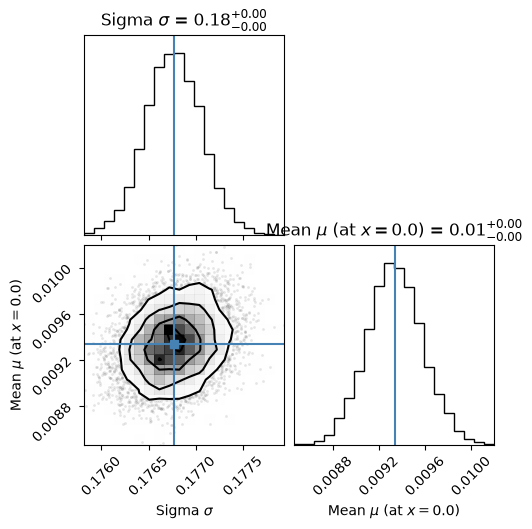

m bin:  [7, 9]
z bin:  [7.5, 8.5]
Number of gals in bin:  484
yerr : [7.22354182e-05 2.04312616e-04 1.02156308e-04 1.76939916e-04
 1.76939916e-04 2.88941673e-04 4.79155557e-04 5.35712199e-04
 6.69883710e-04 8.63809965e-04 1.01900597e-03 1.24068405e-03
 1.55432090e-03 1.78115609e-03 1.98745878e-03 2.22410026e-03
 2.60047505e-03 2.96693296e-03 3.50472076e-03 4.27411543e-03
 5.31507402e-03 6.49396008e-03 8.04865947e-03 1.00144449e-02
 1.28520187e-02 1.44232262e-02 1.26081330e-02 1.04424536e-02
 8.80650184e-03 7.54263683e-03 6.60549355e-03 5.69607305e-03
 5.02386817e-03 4.43998158e-03 3.81892472e-03 3.43934666e-03
 3.04847158e-03 2.81903289e-03 2.56918545e-03 2.18624046e-03
 1.83312941e-03 1.56602655e-03 1.33976742e-03 1.02156308e-03
 8.99323704e-04 7.33109426e-04 5.15864069e-04 2.60448504e-04
 2.60448504e-04 1.91116952e-04]
Guesses: sig = 0.163, mean = -0.006


100%|██████████| 5000/5000 [00:06<00:00, 718.64it/s]


Median sigma: 0.188, mean: 0.008, amplitude: 2.118


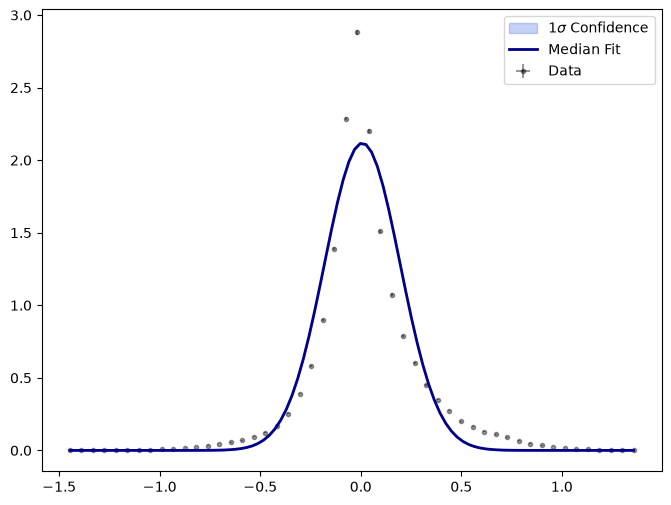

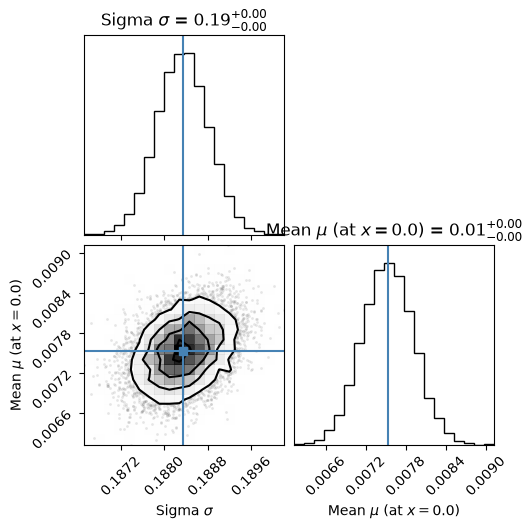

m bin:  [7, 9]
z bin:  [9.5, 10.5]
Number of gals in bin:  116
yerr : [0.00026729 0.00037801 0.00026729 0.00084526 0.00113404 0.00146403
 0.00130947 0.00189006 0.00220417 0.00273896 0.00319638 0.00347483
 0.00465277 0.00535257 0.0057639  0.00621137 0.00686692 0.00754605
 0.00812066 0.00964856 0.01077499 0.01205792 0.0137026  0.01594833
 0.01720888 0.01929157 0.02134344 0.02018384 0.01817407 0.01606661
 0.01388132 0.01189086 0.01037296 0.00927093 0.0084526  0.00778833
 0.00734453 0.00653097 0.00588048 0.00534589 0.00468338 0.00409755
 0.00346453 0.00291584 0.00231484 0.00187106 0.00141439 0.00096374
 0.00053459 0.00046297]
Guesses: sig = 0.276, mean = -0.002


100%|██████████| 5000/5000 [00:07<00:00, 668.49it/s]


Median sigma: 0.324, mean: -0.005, amplitude: 1.232


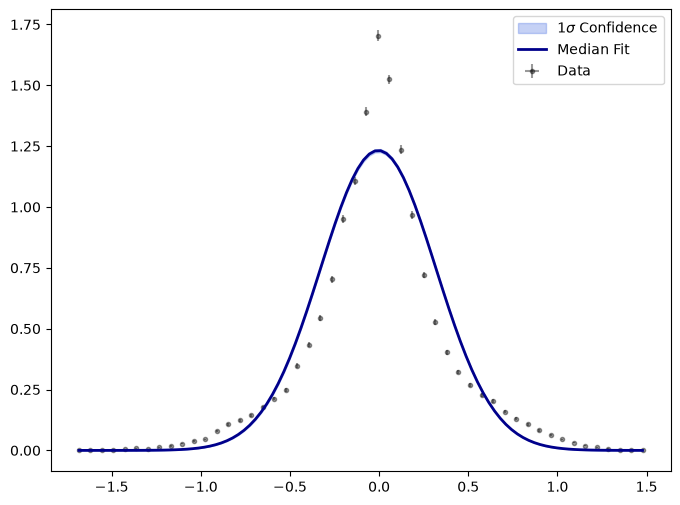

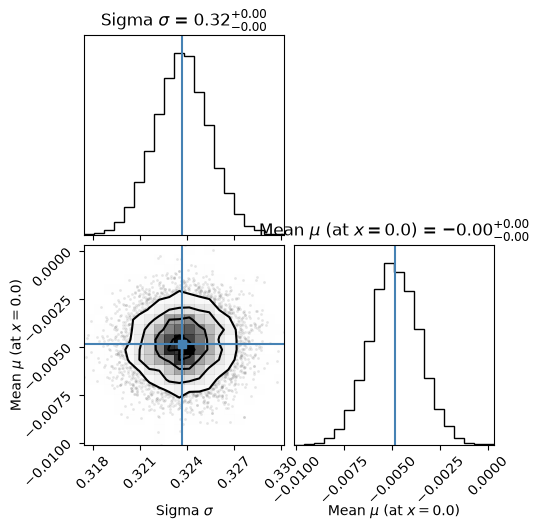

m bin:  [7, 9]
z bin:  [10.5, 13.5]
Number of gals in bin:  144
yerr : [0.00053616 0.00097187 0.00192249 0.00209621 0.00260306 0.00257929
 0.0032864  0.00379661 0.00381818 0.00380741 0.00450408 0.00487199
 0.00564512 0.00622627 0.00657592 0.00715608 0.0077802  0.00832091
 0.00878661 0.00907401 0.00950935 0.00994421 0.01100474 0.01236485
 0.01418246 0.01644448 0.01702122 0.01496854 0.01314403 0.01195279
 0.01086201 0.01010196 0.00899218 0.00821412 0.007199   0.00656967
 0.00605914 0.00536921 0.00475252 0.00415305 0.00388218 0.00365329
 0.00308664 0.00207652 0.00152996 0.00129758 0.00078485 0.00083554
 0.00067211 0.00049638]
Guesses: sig = 0.373, mean = 0.011


100%|██████████| 5000/5000 [00:08<00:00, 612.38it/s]


Median sigma: 0.451, mean: -0.024, amplitude: 0.884


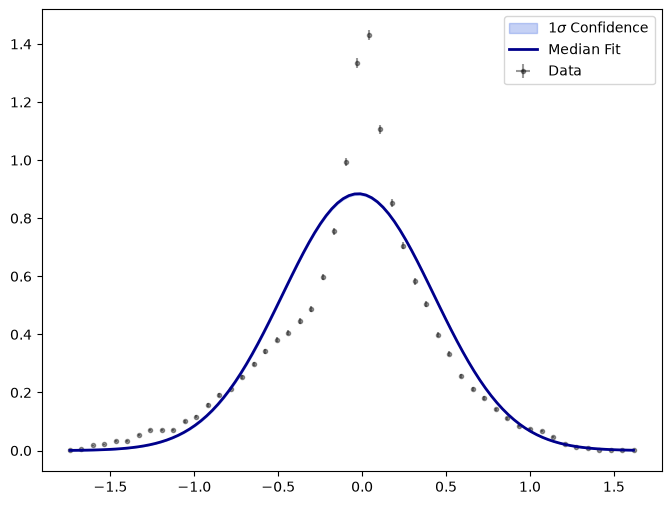

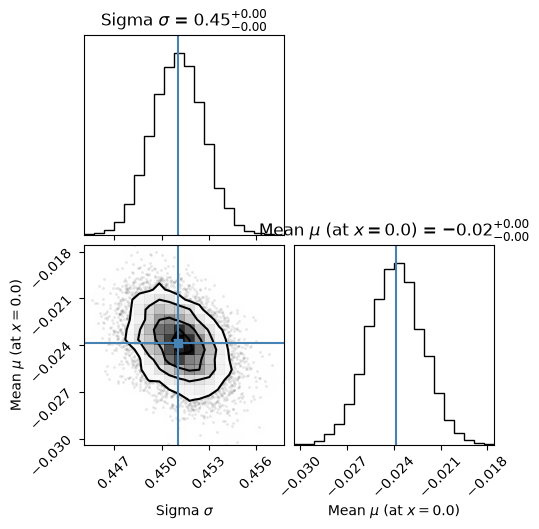

m bin:  [6, 7]
z bin:  [6.5, 7.5]
Number of gals in bin:  206
yerr : [0.00068363 0.00110761 0.00150941 0.00214827 0.00285983 0.00304772
 0.00409465 0.00513292 0.00709626 0.00866418 0.01070596 0.01300021
 0.01715216 0.02186948 0.0274954  0.02998927 0.02670426 0.02282239
 0.01952538 0.01683417 0.01522132 0.01382133 0.01228871 0.0108469
 0.01006179 0.00908546 0.00823199 0.00730717 0.00668508 0.00609543
 0.00547971 0.00502363 0.00440398 0.00394941 0.00355225 0.00308581
 0.00240488 0.00209318 0.00185653 0.0016919  0.00130159 0.00115915
 0.0009668  0.0007251  0.00068363 0.00041864 0.0002417  0.00041864
 0.0002417  0.0002417 ]
Guesses: sig = 0.125, mean = -0.011


100%|██████████| 5000/5000 [00:08<00:00, 624.31it/s]


Median sigma: 0.139, mean: 0.006, amplitude: 2.861


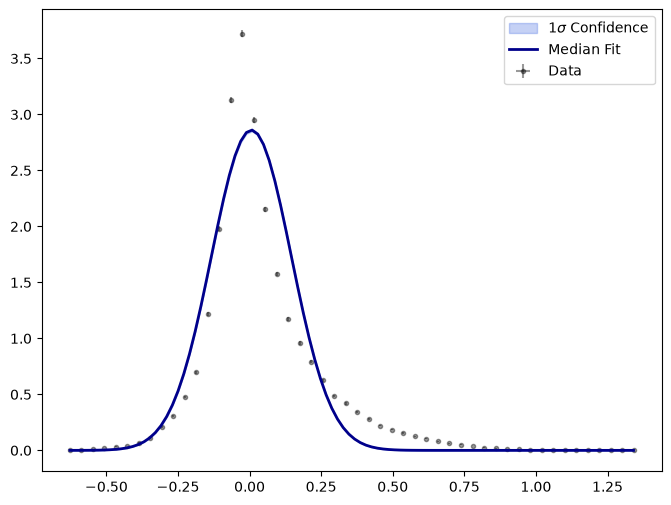

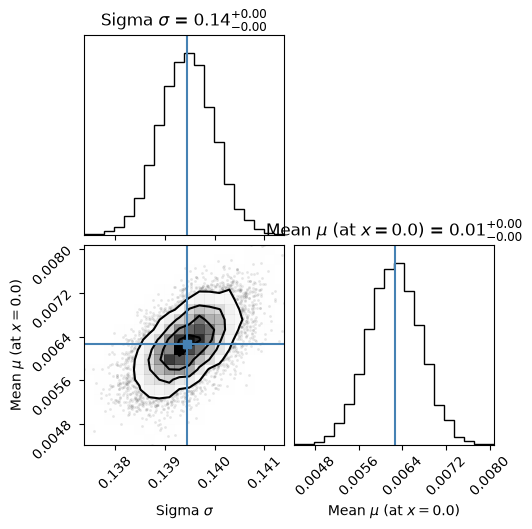

m bin:  [6, 7]
z bin:  [7.5, 8.5]
Number of gals in bin:  60
yerr : [0.0021164  0.00239977 0.00265305 0.00288417 0.00536606 0.01008667
 0.01024404 0.01197218 0.0155934  0.01954503 0.02513088 0.0313301
 0.03916365 0.04854561 0.05431248 0.04620907 0.03997223 0.03466546
 0.03021768 0.02727966 0.02310107 0.02181904 0.01892967 0.01715647
 0.01511413 0.01453135 0.01311974 0.01164708 0.01114166 0.01105518
 0.0095991  0.00857824 0.00795915 0.00733143 0.00683456 0.00614434
 0.00536606 0.00415653 0.0038363  0.0031997  0.00252958 0.00252958
 0.00239977 0.00178869 0.00113126 0.00113126 0.00113126 0.00079992
 0.00079992 0.00113126]
Guesses: sig = 0.131, mean = -0.011


100%|██████████| 5000/5000 [00:07<00:00, 659.73it/s]


Median sigma: 0.145, mean: 0.005, amplitude: 2.759


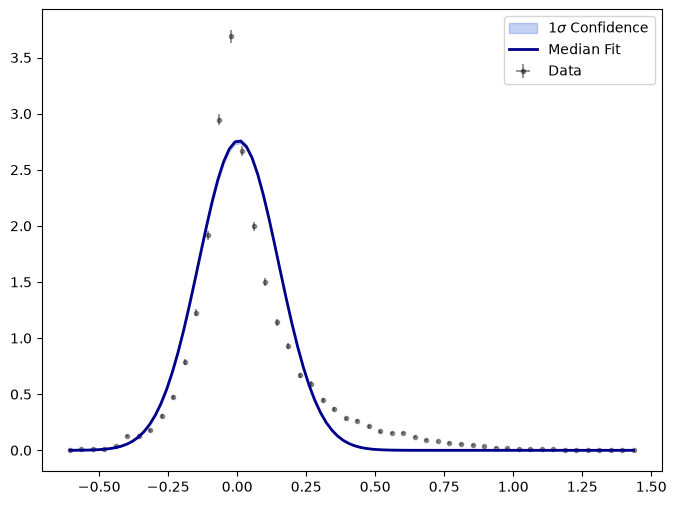

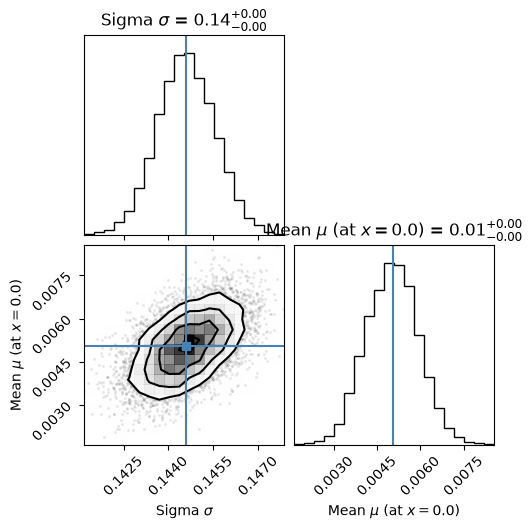

m bin:  [6, 7]
z bin:  [9.5, 10.5]
Number of gals in bin:  3
yerr : [0.04601869 0.04601869 0.09991765 0.1058001  0.12421393 0.14552387
 0.11924334 0.1254258  0.12299012 0.13584703 0.14023031 0.13914744
 0.14962394 0.12781508 0.11667867 0.1254258  0.10290092 0.11137229
 0.09991765 0.1072203  0.10436058 0.09684252 0.10436058 0.11405634
 0.08868944 0.11137229 0.09203738 0.11000571 0.08868944 0.08521005
 0.07379407 0.07171495 0.06025261 0.07970671 0.06508025 0.07379407
 0.07778578 0.07778578 0.0758162  0.0627129  0.05768748 0.0627129
 0.06025261 0.05500285 0.06025261 0.05218029 0.04601869 0.0301263
 0.02459802 0.02459802]
Guesses: sig = 0.449, mean = -0.075


100%|██████████| 5000/5000 [00:07<00:00, 651.73it/s]


Median sigma: 0.512, mean: 0.043, amplitude: 0.778


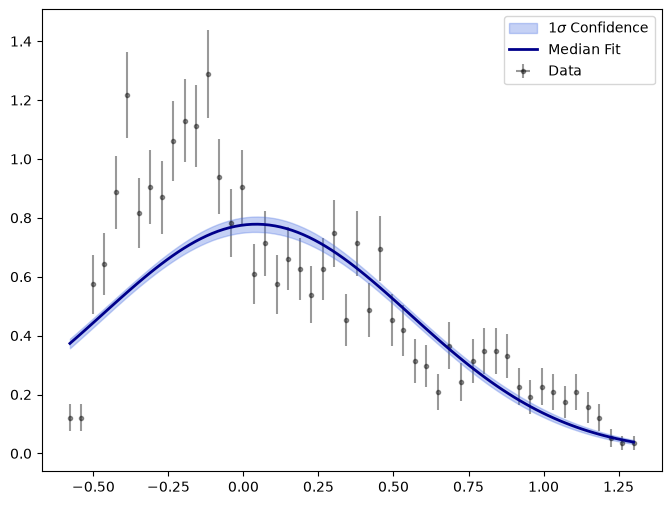

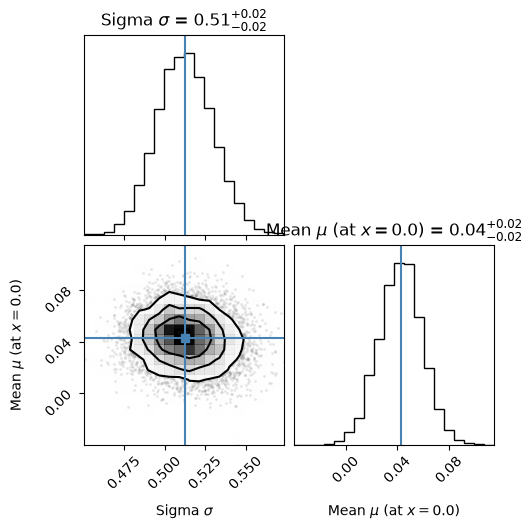

m bin:  [6, 7]
z bin:  [10.5, 13.5]
Number of gals in bin:  5
yerr : [0.03918428 0.05365529 0.04995036 0.04995036 0.05795434 0.07264961
 0.08761872 0.09241595 0.07588004 0.09548029 0.13179266 0.1579569
 0.13679469 0.12352376 0.1116924  0.0984493  0.09031531 0.09241595
 0.09990072 0.0801843  0.06644019 0.0685725  0.06644019 0.05958717
 0.06117644 0.04594765 0.03918428 0.05183594 0.04380936 0.04489124
 0.04380936 0.04380936 0.04156121 0.02938821 0.04270008 0.04156121
 0.04995036 0.04594765 0.04594765 0.04156121 0.04156121 0.03248989
 0.03393459 0.0309779  0.04039024 0.03248989 0.02938821 0.02938821
 0.00979607 0.01696729]
Guesses: sig = 0.245, mean = -0.034


100%|██████████| 5000/5000 [00:06<00:00, 739.28it/s]


Median sigma: 0.279, mean: -0.004, amplitude: 1.432


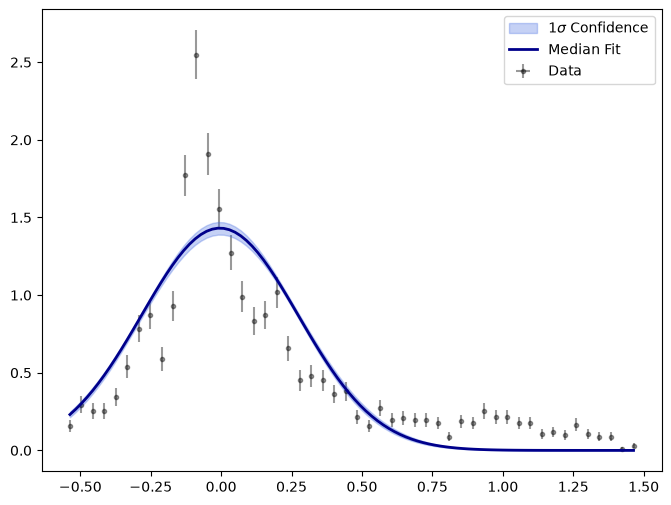

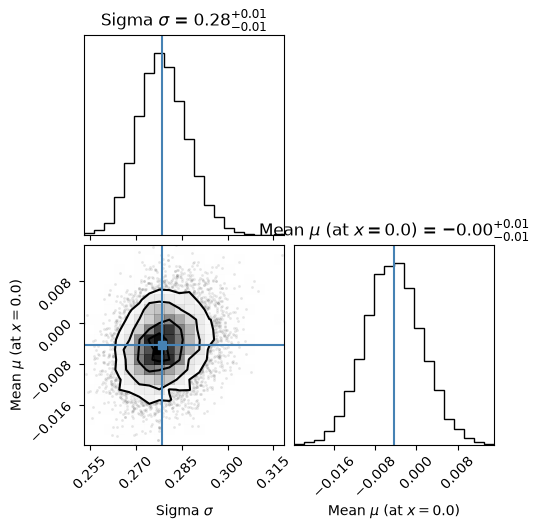

<Figure size 640x480 with 0 Axes>

In [132]:
if __name__ == "__main__":

    with fits.open('/raid/scratch/work/alberttg/Masters_project/Data_products/First_sample_table.fits') as hdu:

        sample_table = hdu[1].data
    sample_table = Table(sample_table)

    SFH_models = ["Bagpipes_sfh_cont_bursty_zEAZYsfhzblueagn_3.0,10.0Myr_Calzetti_log_10_Z_log_10_BPASS_zfix"]

    get_posterior(sample_table, SFH_models[0])